Rodrigo Baptista - ist1114851
João Silva - ist1113812

In [1]:
# imports e dados

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from lime.lime_tabular import LimeTabularExplainer

df = pd.read_csv("heart.csv")
features = [c for c in df.columns if c != "outcome"]
X, y = df[features], df["outcome"]
print(df.shape, y.value_counts().to_dict())

(284, 10) {0: 181, 1: 103}


In [2]:
# II.1a (kNN vs NB, 5-fold)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def assess(model, name):
    r = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "recall"])
    acc, rec = r["test_accuracy"], r["test_recall"]
    print(f"{name:<14} acc {acc.mean():.4f} ± {acc.std():.4f} | recall {rec.mean():.4f} ± {rec.std():.4f}")
    return {"model": name, "acc_mean": acc.mean(), "acc_std": acc.std(),
            "rec_mean": rec.mean(), "rec_std": rec.std()}

res = [assess(KNeighborsClassifier(n_neighbors=5), "kNN"),
       assess(GaussianNB(), "Naive Bayes")]
pd.DataFrame(res)

kNN            acc 0.5915 ± 0.0329 | recall 0.3286 ± 0.0885
Naive Bayes    acc 0.8167 ± 0.0360 | recall 0.7662 ± 0.0410


,model,acc_mean,acc_std,rec_mean,rec_std
0,kNN,0.591479,0.032946,0.328571,0.088525
1,Naive Bayes,0.816667,0.035997,0.766190,0.041030


# II.1a 

O Naïve Bayes tem melhor accuracy (0.817 vs 0.591) e recall (0.766 vs 0.329) do que o kNN, e também é mais estável: os desvios-padrão são menores (0.036 vs 0.033 na accuracy é semelhante, mas 0.041 vs 0.089 no recall). O kNN sem scaling tem um recall muito baixo, deixando passar a maioria dos doentes.

In [3]:
# II.1b (com MinMax)

res_mm = [assess(make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)), "kNN + MinMax"),
          assess(make_pipeline(MinMaxScaler(), GaussianNB()), "NB + MinMax")]
pd.DataFrame(res + res_mm)

kNN + MinMax   acc 0.7920 ± 0.0453 | recall 0.6295 ± 0.0802
NB + MinMax    acc 0.8167 ± 0.0360 | recall 0.7662 ± 0.0410


,model,acc_mean,acc_std,rec_mean,rec_std
0,kNN,0.591479,0.032946,0.328571,0.088525
1,Naive Bayes,0.816667,0.035997,0.766190,0.041030
2,kNN + MinMax,0.791980,0.045252,0.629524,0.080159
3,NB + MinMax,0.816667,0.035997,0.766190,0.041030


# II.1b

O Min-Max não altera o Naïve Bayes: cada variável é modelada por uma gaussiana por classe, e uma transformação linear só reescala a média e a variância sem mudar a decisão. O kNN melhora muito (accuracy 0.592→0.792, recall 0.329→0.630), porque a distância passa a ser calculada em escalas comparáveis. Sem scaling, trestbps e thalach (centenas) dominam a distância e as variáveis binárias e oldpeak quase não contam.

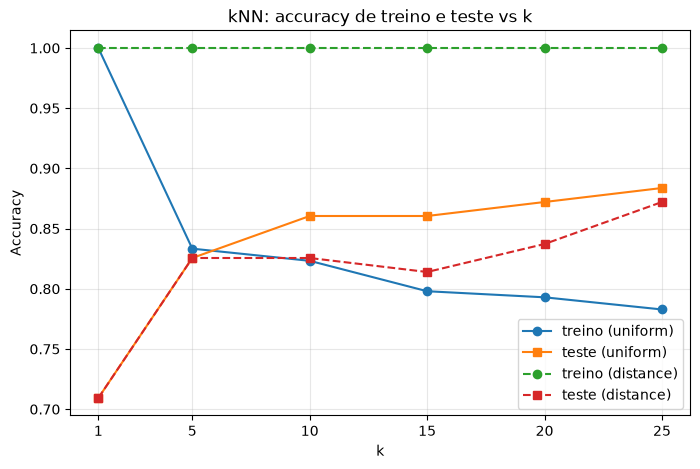

In [4]:
# II.2a (k e weights, gráfico)

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.3, stratify=y, random_state=0)

ks = [1, 5, 10, 15, 20, 25]
acc = {}
for w in ["uniform", "distance"]:
    tr, te = [], []
    for k in ks:
        m = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k, weights=w))
        m.fit(X_train, y_train)
        tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
    acc[w] = (tr, te)

plt.figure(figsize=(8, 5))
for w, ls in [("uniform", "-"), ("distance", "--")]:
    plt.plot(ks, acc[w][0], "o" + ls, label=f"treino ({w})")
    plt.plot(ks, acc[w][1], "s" + ls, label=f"teste ({w})")
plt.xticks(ks); plt.xlabel("k"); plt.ylabel("Accuracy")
plt.title("kNN: accuracy de treino e teste vs k"); plt.grid(alpha=0.3); plt.legend()
plt.show()

# II.2b

Com k=1 há overfitting (treino 1.0, teste 0.709). Ao aumentar k, a fronteira suaviza-se: a accuracy de treino desce (uniform) e a de teste sobe, ou seja, há menos variância à custa de mais enviesamento (k muito grande tenderia ao underfitting, perdendo estrutura local). Com weights="distance" o treino é sempre 1.0, pois cada ponto de treino é o seu próprio vizinho a distância 0, pelo que esta accuracy de treino não mede generalização. No teste, uniform é igual ou melhor do que distance (0.884 vs 0.872 em k=25). A accuracy de teste sobe até k=25 e as diferenças entre k=10 e k=25 são de 1 a 2 observações em 86, pelo que não justificam um único valor. Propomos então um intervalo de k entre 10 e 25 com pesos uniformes.

In [5]:
# II.3, pipelines e função LIME

knn = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
nb  = make_pipeline(MinMaxScaler(), GaussianNB()).fit(X_train, y_train)
pred_knn, pred_nb = knn.predict(X_test), nb.predict(X_test)

def explain(model, x, seed=0, num_samples=5000):
    explainer = LimeTabularExplainer(
        X_train, feature_names=features,
        class_names=["no disease", "disease"],
        mode="classification", random_state=seed)
    return explainer.explain_instance(
        x, model.predict_proba, num_features=5, num_samples=num_samples)

paciente: 1 {'age': np.float64(52.0), 'sex': np.float64(1.0), 'chest_pain': np.float64(4.0), 'trestbps': np.float64(112.0), 'fasting_blood_sugar': np.float64(0.0), 'restecg': np.float64(1.0), 'thalach': np.float64(96.0), 'exercise_induce_angina': np.float64(1.0), 'oldpeak': np.float64(1.0)}

kNN | R2 = 0.537
  0.00 < exercise_induce_angina <= 1.00 +0.2896
  3.00 < chest_pain <= 4.00           +0.2648
  fasting_blood_sugar <= 0.00         -0.2546
  0.00 < sex <= 1.00                  +0.2117
  thalach <= 120.00                   +0.0321


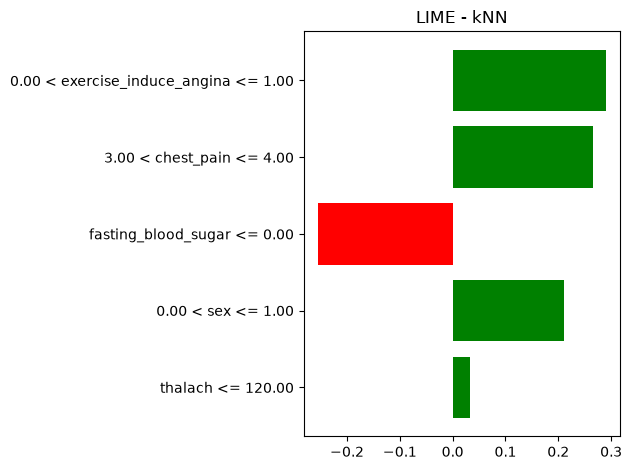


Naive Bayes | R2 = 0.454
  fasting_blood_sugar <= 0.00         -0.6763
  0.00 < exercise_induce_angina <= 1.00 +0.3741
  0.00 < sex <= 1.00                  +0.2657
  3.00 < chest_pain <= 4.00           +0.1679
  restecg > 0.00                      -0.1283


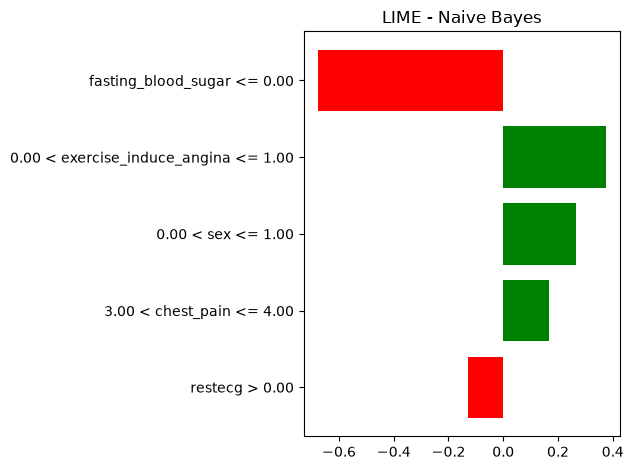

In [6]:
# II.3a, LIME dos dois modelos

i_a = next(i for i in range(len(y_test))
           if y_test[i] == 1 and pred_knn[i] == 1 and pred_nb[i] == 1)
print("paciente:", i_a, dict(zip(features, X_test[i_a])))

for name, model in [("kNN", knn), ("Naive Bayes", nb)]:
    exp = explain(model, X_test[i_a])
    print(f"\n{name} | R2 = {exp.score:.3f}")
    for cond, w in exp.as_list(): print(f"  {cond:<35} {w:+.4f}")
    exp.as_pyplot_figure(); plt.title(f"LIME - {name}"); plt.tight_layout(); plt.show()

In [7]:
# II.3a, parâmetros do NB

j = features.index("fasting_blood_sugar")
gnb = nb[-1]
print("média por classe [0,1]:", gnb.theta_[:, j])
print("variância por classe  :", gnb.var_[:, j])
print("valor escalado do paciente:", nb[0].transform(X_test[i_a].reshape(1, -1))[0, j])

média por classe [0,1]: [0.02380952 0.13888889]
variância por classe  : [0.02324263 0.11959877]
valor escalado do paciente: 0.0


# II.3a

Relativamente à interpretação do paciente 1 (que é doente), ambos os modelos preveem corretamente a doença, embora com dinâmicas diferentes. O kNN destaca como fatores positivos a presença de angina induzida por exercício (exercise_induce_angina > 0), dor no peito de grau elevado (chest_pain entre 3 e 4) e o sexo (sex), com um R² de 0.537. Por sua vez, o Naïve Bayes dá grande ênfase à glicemia em jejum (fasting_blood_sugar <= 0) como fator que contraria a doença, mas que acaba por ser superado pelo impacto positivo das restantes variáveis clínicas, obtendo um R² de 0.454.


paciente: 3 {'age': np.float64(39.0), 'sex': np.float64(1.0), 'chest_pain': np.float64(4.0), 'trestbps': np.float64(110.0), 'fasting_blood_sugar': np.float64(0.0), 'restecg': np.float64(0.0), 'thalach': np.float64(150.0), 'exercise_induce_angina': np.float64(0.0), 'oldpeak': np.float64(0.0)}
pred kNN: 0 | pred NB: 0

kNN | P(disease)=0.400 | R2 = 0.572
  exercise_induce_angina <= 0.00      -0.2875
  3.00 < chest_pain <= 4.00           +0.2712
  fasting_blood_sugar <= 0.00         -0.2488
  0.00 < sex <= 1.00                  +0.2072
  oldpeak <= 0.00                     -0.1234


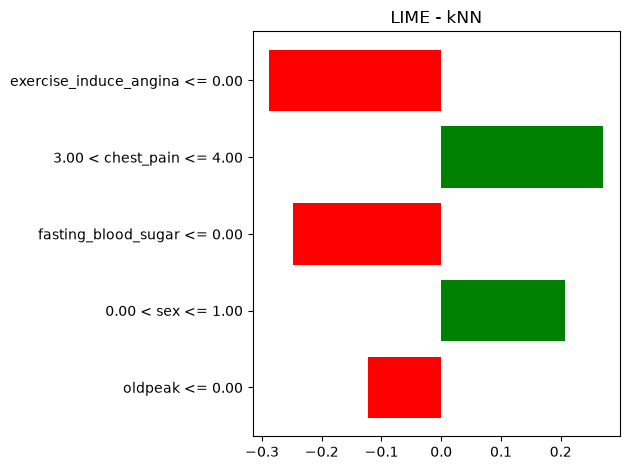


Naive Bayes | P(disease)=0.049 | R2 = 0.634
  fasting_blood_sugar <= 0.00         -0.6844
  oldpeak <= 0.00                     -0.3892
  exercise_induce_angina <= 0.00      -0.3702
  0.00 < sex <= 1.00                  +0.2521
  3.00 < chest_pain <= 4.00           +0.1557


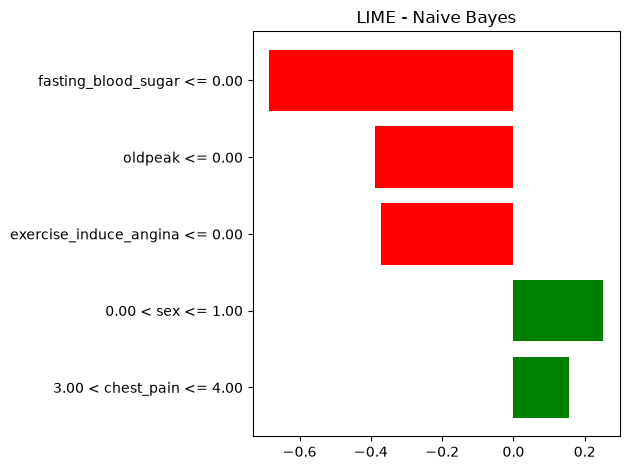

In [8]:
# II.3b, falso negativo

i_b = next(i for i in range(len(y_test))
           if y_test[i] == 1 and (pred_knn[i] == 0 or pred_nb[i] == 0))
print("paciente:", i_b, dict(zip(features, X_test[i_b])))
print("pred kNN:", pred_knn[i_b], "| pred NB:", pred_nb[i_b])

for name, model in [("kNN", knn), ("Naive Bayes", nb)]:
    exp = explain(model, X_test[i_b])
    p = model.predict_proba(X_test[i_b].reshape(1, -1))[0, 1]
    print(f"\n{name} | P(disease)={p:.3f} | R2 = {exp.score:.3f}")
    for cond, w in exp.as_list(): print(f"  {cond:<35} {w:+.4f}")
    exp.as_pyplot_figure(); plt.title(f"LIME - {name}"); plt.tight_layout(); plt.show()

# II.3b

Tendp em consideração o paciente 3 (que possui outcome = 1, mas ambos os modelos preveem incorretamente 0, constituindo um falso negativo), os modelos falham na deteção da condição. O kNN atribui uma probabilidade de doença de 0.400, influenciado negativamente por variáveis como exercise_induce_angina <= 0 e fasting_blood_sugar <= 0. O Naïve Bayes apresenta uma probabilidade de doença ainda mais baixa, fixando-se em 0.049, penalizado fortemente pelos valores a zero de fasting_blood_sugar, oldpeak e exercise_induce_angina, o que mascara o sintoma de dor no peito (chest_pain = 4).

In [9]:
# II.3c, estabilidade

from collections import defaultdict

for ns in [500, 5000]:
    appear, weights = defaultdict(int), defaultdict(list)
    for seed in range(10):
        exp = explain(knn, X_test[i_a], seed=seed, num_samples=ns)
        for fid, w in exp.as_map()[1]:
            appear[features[fid]] += 1
            weights[features[fid]].append(w)
    out = pd.DataFrame({"n_top5": pd.Series(appear),
                        "mean_w": {f: np.mean(v) for f, v in weights.items()},
                        "std_w":  {f: np.std(v)  for f, v in weights.items()}})
    print(f"\nnum_samples = {ns}")
    display(out.sort_values("n_top5", ascending=False))


num_samples = 500


,n_top5,mean_w,std_w
chest_pain,10,0.271911,0.020119
exercise_induce_angina,10,0.278348,0.024843
sex,10,0.206770,0.017326
fasting_blood_sugar,10,-0.204970,0.037907
restecg,3,-0.029340,0.002744
thalach,3,0.033863,0.014203
oldpeak,2,-0.029429,0.008105
trestbps,1,0.038738,0.000000
age,1,0.032582,0.000000



num_samples = 5000


,n_top5,mean_w,std_w
exercise_induce_angina,10,0.295019,0.007816
chest_pain,10,0.256237,0.005736
fasting_blood_sugar,10,-0.241119,0.012190
sex,10,0.215714,0.004633
thalach,5,0.024295,0.006572
age,3,0.016868,0.005991
restecg,1,-0.012892,0.000000
oldpeak,1,-0.014384,0.000000


# II.3c

Observa-se que, ao alterar o número de amostras locais (num_samples), as variáveis clínicas mais relevantes — tais como chest_pain, exercise_induce_angina e sex — mantêm-se de forma consistente no topo dos preditores com pesos estáveis, registrando-se apenas pequenas oscilações nos pesos exatos e na ordem de importância de atributos secundários devido à natureza estocástica inerente à amostragem do LIME.

# II.4

O Naïve Bayes demonstra um desempenho superior e mais estável em termos de accuracy (cerca de 0.817) e recall (cerca de 0.766) face ao kNN sem normalização. O kNN revela-se altamente sensível à escala das variáveis, exigindo obrigatoriamente a aplicação de pré-processamento (como o MinMaxScaler) para alcançar resultados competitivos. Além disso, a interpretabilidade proporcionada pelo LIME valida o comportamento lógico dos classificadores, comprovando que sintomas críticos como a dor no peito e a angina induzida por exercício exercem o peso clínico esperado nas decisões, embora persistam desafios na deteção de perfis atípicos que originam falsos negativos.